# 1. Scaricare i dati da argopy

In [2]:
from datetime import datetime
from argopy import DataFetcher, ArgoIndex
from src.storage.cache_manager import MemoryManager
from src.processing.conversions import convert_mmol
from src.processing.netcdf_formatter import convert_argo_to_standard
%load_ext autoreload
%autoreload 2
from src.loaders.argo_loader import ArgopyLoader

loader = ArgopyLoader()

def download_profiles(start, end, mode="standard", params=None):
    region = [-5, 36, 30, 46, 0, 2000, start, end]
    if params is None: params = ['DOXY']
    return loader.fetch_profiles(params=params, region=region, mode=mode)

def save_profiles(p, mm):
    p = convert_mmol(p)
    p = convert_argo_to_standard(p)
    mm.save_profiles(p)
    return mm


## Performance with cache

Using the option cache=True which is on by default in the fetch profile method of the argopy loader class, it takes significantly less time! ~20 times less time.

In [16]:
cached_profiles = download_profiles(start="2025-01-01", end="2025-02-01")

In [17]:
cached_profiles_copy = download_profiles(start="2025-01-01", end="2025-02-01")

# 2. Preprocessing dei dati in input per il modello


## Check differences in argopy vs carolina

In [6]:
from src.graphics.plotter import plot_similar_comparison
from src.storage.cache_manager import MemoryManager

standard_memory = MemoryManager(dir_name="data_standard")
superfloat_memory = MemoryManager(dir_name="data_example")
expert_memory = MemoryManager(dir_name="data_expert")

In [46]:
e_profiles = download_profiles("2020-06-01", "2020-08-01", "expert")
em = save_profiles(e_profiles, expert_memory)

Saving 459 profiles...
data/data_expert/6903262/SD6903262_089.nc SAVED.
data/data_expert/6903263/SD6903263_088.nc SAVED.
data/data_expert/6903288/S6903288_057.nc SAVED.
data/data_expert/6903249/SD6903249_136.nc SAVED.
data/data_expert/7900562/SD7900562_058.nc SAVED.
data/data_expert/6903249/SD6903249_137.nc SAVED.
data/data_expert/6903765/SD6903765_045.nc SAVED.
data/data_expert/6903246/SD6903246_118.nc SAVED.
data/data_expert/6902902/S6902902_163.nc SAVED.
data/data_expert/6903247/SD6903247_137.nc SAVED.
data/data_expert/6902969/SD6902969_099.nc SAVED.
data/data_expert/6903247/SD6903247_138.nc SAVED.
data/data_expert/6902899/S6902899_060.nc SAVED.
data/data_expert/6902803/SD6902803_231.nc SAVED.
data/data_expert/6902804/SD6902804_233.nc SAVED.
data/data_expert/6902898/S6902898_219.nc SAVED.
data/data_expert/6903288/S6903288_058.nc SAVED.
data/data_expert/6902870/SD6902870_096.nc SAVED.
data/data_expert/6902873/SD6902873_104.nc SAVED.
data/data_expert/6902875/SD6902875_096.nc SAVED.
da

In [50]:
expert_paths = expert_memory.get_profiles_paths()
print(len(expert_paths))
standard_paths = standard_memory.get_profiles_paths()
print(len(standard_paths))
superfloat_paths = superfloat_memory.get_profiles_paths()
print(len(superfloat_paths))


420
80
16631


In [96]:
import numpy as np
import pandas as pd

def get_profile_name(p):
    import os
    return os.path.basename(p).replace("SD", "")

expert_profile_names = set([get_profile_name(p) for p in expert_paths])
standard_profile_names = set([get_profile_name(p) for p in standard_paths])
superfloat_profile_names = set([get_profile_name(p) for p in superfloat_paths])

common_paths = expert_profile_names & standard_profile_names & superfloat_profile_names
print(len(common_paths))

25


Comparisons for 6903246_128.nc


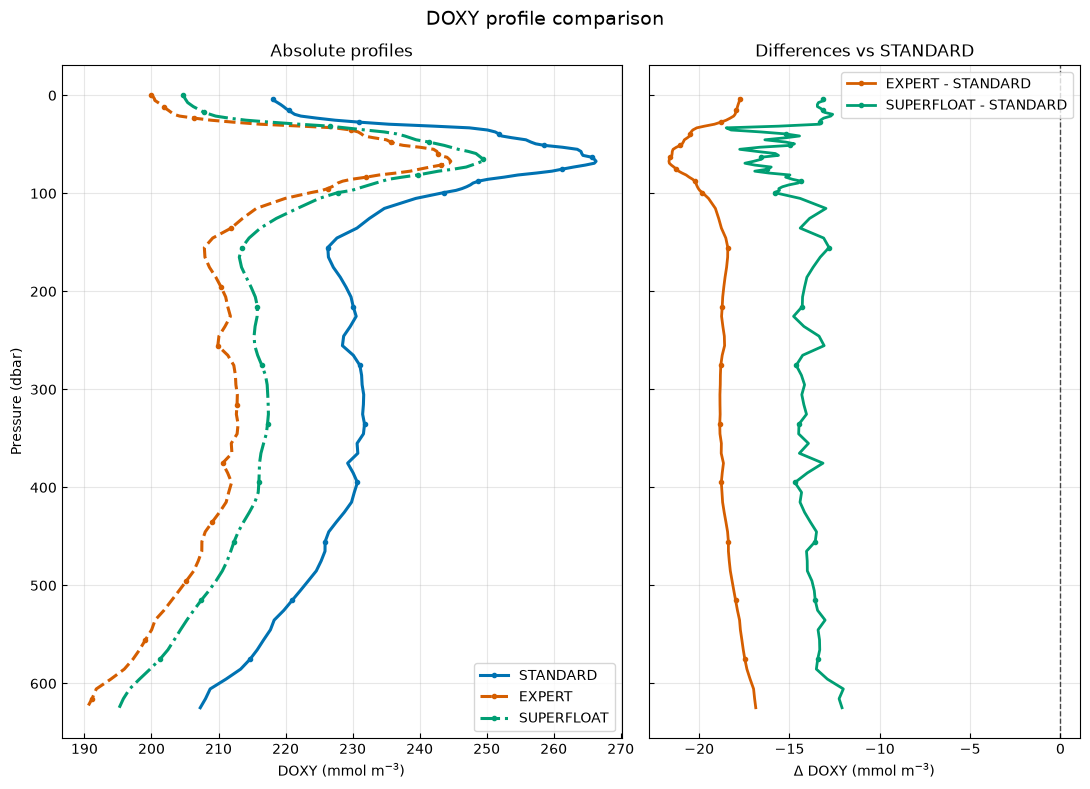

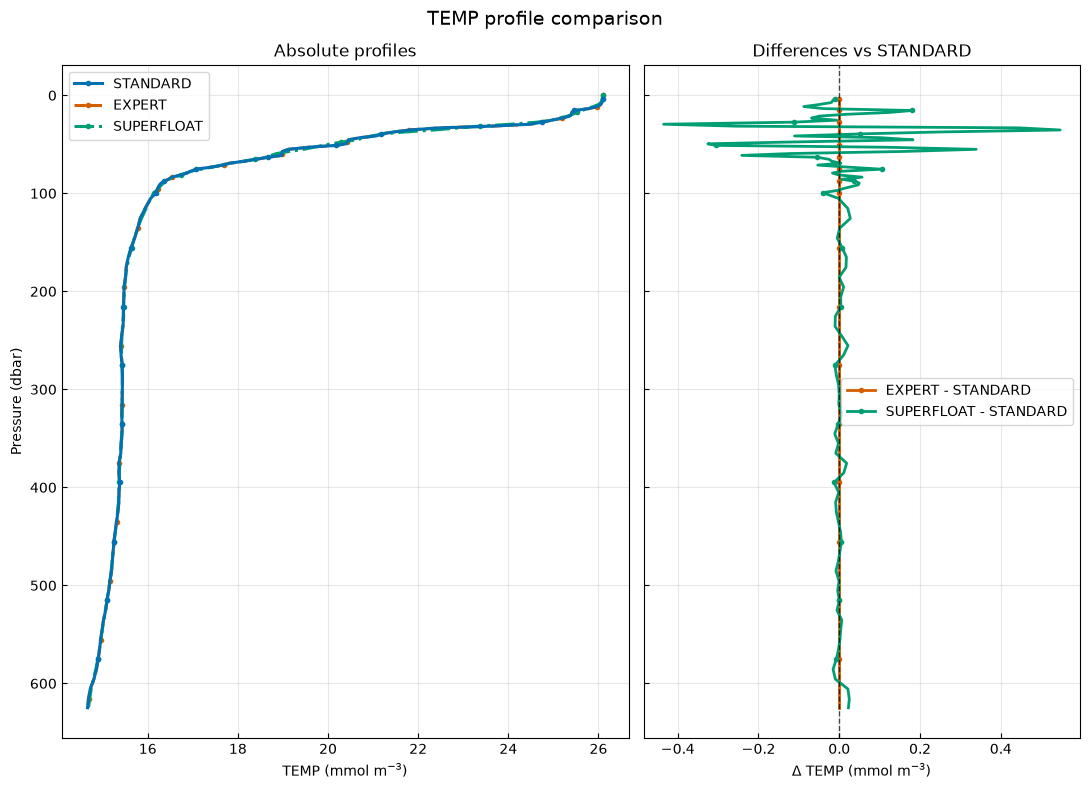

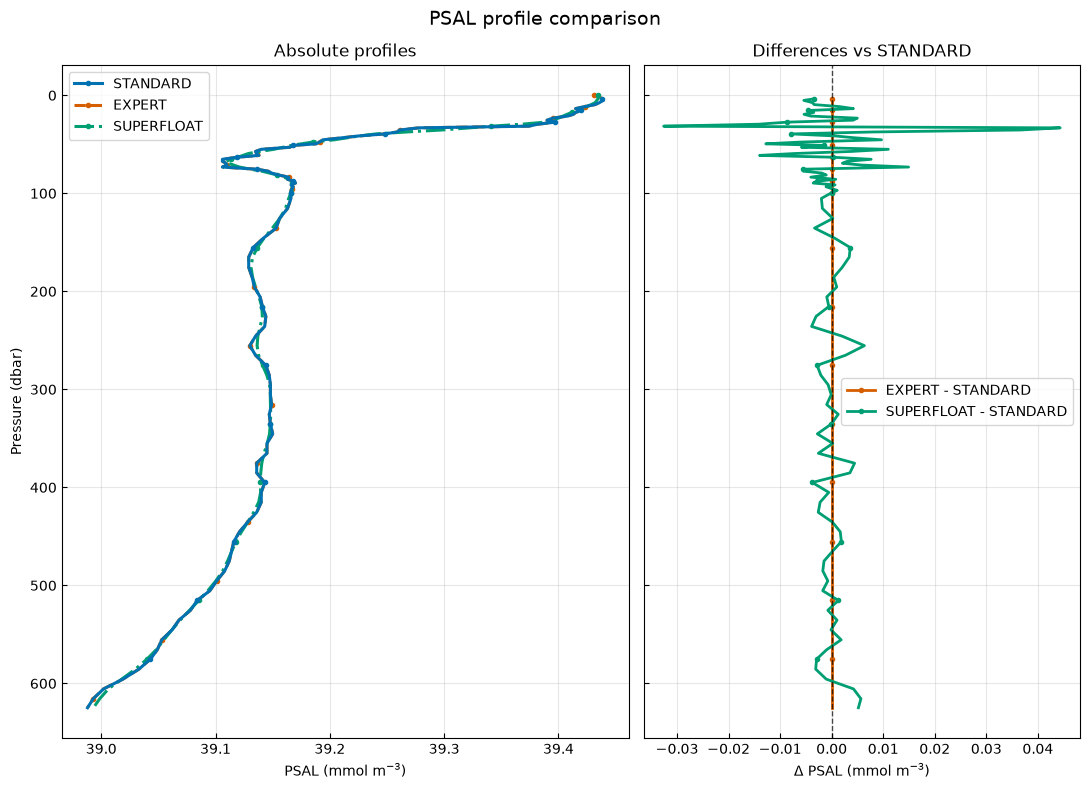

In [95]:
profile_name = common_paths.pop().replace(".nc", '')

print("Comparisons for", profile_name)
name_profiles = {"STANDARD": standard_memory.load_profile(profile_name),
                 "EXPERT": expert_memory.load_profile(profile_name),#}
                 "SUPERFLOAT": superfloat_memory.load_profile(profile_name)}


plot_similar_comparison(name_profiles=name_profiles, attr="DOXY", title=f"{profile_name}")
plot_similar_comparison(name_profiles=name_profiles, attr="TEMP", title=f"{profile_name}")
plot_similar_comparison(name_profiles=name_profiles, attr="PSAL", title=f"{profile_name}")


In [14]:

differences = []
for path in common_paths:
    ds_std = standard_memory.load_profile(path)
    ds_exp = expert_memory.load_profile(path)

    if ds_std is None or ds_exp is None:
        continue

    # Esempio su DOXY o TEMP (assicurati che le dimensioni combacino)
    if 'DOXY' in ds_std and 'DOXY' in ds_exp:
        diff = np.nanmean(np.abs(ds_exp['DOXY'] - ds_std['DOXY']))
        differences.append({'path': path, 'mean_diff_doxy': diff})

df_diff = pd.DataFrame(differences)
print(df_diff.describe())  # Vedi subito se ci sono variazioni significative

/var/folders/6b/kdhvc02d60s28_j0gc62tsz80000gn/T/ipykernel_44716/3671622827.py:16: RuntimeWarning: Mean of empty slice
  diff = np.nanmean(np.abs(ds_exp['DOXY'] - ds_std['DOXY']))


       mean_diff_doxy
count       99.000000
mean        17.507455
std         11.475604
min          3.682145
25%          8.137464
50%         15.501328
75%         23.130952
max         52.204271


In [99]:
test = MemoryManager(dir_name="")
save_profiles(profiles, test)

Saving 84 profiles...
data/test/6903262/SD6903262_095.nc SAVED.
data/test/6903781/SD6903781_002.nc SAVED.
data/test/6903263/SD6903263_094.nc SAVED.
data/test/6903246/SD6903246_124.nc SAVED.
data/test/6902904/SD6902904_154.nc SAVED.
data/test/6903247/SD6903247_143.nc SAVED.
data/test/6901775/SD6901775_155.nc SAVED.
data/test/6903266/SD6903266_237.nc SAVED.
data/test/6903237/SD6903237_169.nc SAVED.
data/test/6901774/SD6901774_111.nc SAVED.
data/test/6903250/SD6903250_140.nc SAVED.
data/test/6903781/SD6903781_003.nc SAVED.
data/test/6903262/SD6903262_096.nc SAVED.
data/test/6903263/SD6903263_095.nc SAVED.
data/test/6903246/SD6903246_125.nc SAVED.
data/test/6903247/SD6903247_144.nc SAVED.
data/test/6903266/SD6903266_238.nc SAVED.
data/test/6902904/SD6902904_155.nc SAVED.
data/test/6903237/SD6903237_170.nc SAVED.
data/test/6903250/SD6903250_141.nc SAVED.
data/test/6903262/SD6903262_097.nc SAVED.
data/test/6903781/SD6903781_004.nc SAVED.
data/test/6903263/SD6903263_096.nc SAVED.
data/test/69

## Check differenze expert e standard

In [2]:
%load_ext autoreload
%autoreload 2
from src.storage.cache_manager import MemoryManager

expert_memory = MemoryManager(dir_name="data_expert")
expert_profiles = expert_memory.load_profiles()

standard_memory = MemoryManager(dir_name="data_standard")
standard_profiles = standard_memory.load_profiles()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Loading 420 profiles from memory...
Loading 80 profiles from memory...


In [3]:
expert_profiles.isel(N_PROF=0)

<xarray.Dataset> Size: 204kB
Dimensions:              (DATETIME: 14, nDOXY: 2214, nTEMP: 2214, nPSAL: 2214,
                          nCHLA: 2214, nNITRATE: 2214)
Coordinates:
  * DATETIME             (DATETIME) int64 112B 0 1 2 3 4 5 6 7 8 9 10 11 12 13
  * nDOXY                (nDOXY) int64 18kB 0 1 2 3 4 ... 2210 2211 2212 2213
  * nTEMP                (nTEMP) int64 18kB 0 1 2 3 4 ... 2210 2211 2212 2213
  * nPSAL                (nPSAL) int64 18kB 0 1 2 3 4 ... 2210 2211 2212 2213
  * nCHLA                (nCHLA) int64 18kB 0 1 2 3 4 ... 2210 2211 2212 2213
  * nNITRATE             (nNITRATE) int64 18kB 0 1 2 3 4 ... 2210 2211 2212 2213
    N_PROF               int64 8B 307
Data variables: (12/17)
    CYCLE_NUMBER         int64 8B 239
    PLATFORM_NUMBER      int64 8B 6903266
    TIME                 datetime64[ns] 8B 2020-07-14T06:02:30
    REFERENCE_DATE_TIME  (DATETIME) |S1 14B b'2' b'0' b'2' ... b'2' b'3' b'0'
    LONGITUDE            float64 8B 3.954
    LATITUDE             float64 8B 37.94
    ...                   ...
    PSAL                 (nPSAL) float32 9kB 36.76 36.77 36.77 ... nan nan nan
    PRES_PSAL            (nPSAL) float32 9kB 0.0 1.3 3.4 5.7 ... nan nan nan nan
    CHLA                 (nCHLA) float64 18kB nan nan nan nan ... nan nan nan
    PRES_CHLA            (nCHLA) float32 9kB 0.0 1.3 3.4 5.7 ... nan nan nan nan
    NITRATE              (nNITRATE) float64 18kB nan nan nan nan ... nan nan nan
    PRES_NITRATE         (nNITRATE) float32 9kB 0.0 1.3 3.4 5.7 ... nan nan nan
Attributes:
    origin:       argopy
    file_origin:  argopy_fetch

In [15]:
params = ["DOXY", "TEMP", "PSAL"]
from src.loaders.argo_loader import ArgopyLoader

loader = ArgopyLoader()
standard_profile = loader.fetch_profile(wmo=6901774, cycle=112, params=params)
expert_profile = loader.fetch_profile(wmo=6901774, cycle=112, params=params, mode="expert")

In [6]:
standard_profile.data_vars

Data variables:
    CYCLE_NUMBER     (N_POINTS) int64 224B 112 112 112 112 ... 112 112 112 112
    DIRECTION        (N_POINTS) <U1 112B 'A' 'A' 'A' 'A' 'A' ... 'A' 'A' 'A' 'A'
    DOXY             (N_POINTS) float32 112B 206.0 215.2 242.0 ... 159.6 166.3
    DOXY_DATA_MODE   (N_POINTS) <U1 112B 'A' 'A' 'A' 'A' 'A' ... 'A' 'A' 'A' 'A'
    DOXY_ERROR       (N_POINTS) float32 112B 8.047 8.165 9.044 ... 9.245 9.049
    DOXY_QC          (N_POINTS) int64 224B 1 1 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1 1
    PLATFORM_NUMBER  (N_POINTS) int64 224B 6901774 6901774 ... 6901774 6901774
    POSITION_QC      (N_POINTS) int64 224B 1 1 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1 1
    PRES             (N_POINTS) float32 112B 2.4 16.5 44.5 ... 239.5 336.9 635.0
    PRES_DATA_MODE   (N_POINTS) <U1 112B 'D' 'D' 'D' 'D' 'D' ... 'D' 'D' 'D' 'D'
    PRES_ERROR       (N_POINTS) float32 112B 2.4 2.4 2.4 2.4 ... 2.4 2.4 2.4 2.4
    PRES_QC          (N_POINTS) int64 224B 1 1 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1 1
    PSAL            

In [7]:
expert_profile.data_vars

Data variables:
    CONFIG_MISSION_NUMBER  (N_POINTS) int64 10kB 5 5 5 5 5 5 5 ... 5 5 5 5 5 5 5
    CYCLE_NUMBER           (N_POINTS) int64 10kB 112 112 112 112 ... 112 112 112
    DIRECTION              (N_POINTS) <U1 5kB 'A' 'A' 'A' 'A' ... 'A' 'A' 'A'
    DOXY                   (N_POINTS) float32 5kB 185.7 186.8 ... nan 166.8
    DOXY_ADJUSTED          (N_POINTS) float32 5kB 204.5 205.7 ... nan 183.8
    DOXY_ADJUSTED_ERROR    (N_POINTS) float32 5kB 8.041 8.041 ... nan 8.044
    DOXY_ADJUSTED_QC       (N_POINTS) int64 10kB 1 1 1 9 1 9 9 ... 9 9 9 9 9 9 1
    DOXY_DATA_MODE         (N_POINTS) <U1 5kB 'A' 'A' 'A' 'A' ... 'A' 'A' 'A'
    DOXY_QC                (N_POINTS) int64 10kB 3 3 3 9 3 9 9 ... 9 9 9 9 9 9 3
    PLATFORM_NUMBER        (N_POINTS) int64 10kB 6901774 6901774 ... 6901774
    POSITION_QC            (N_POINTS) int64 10kB 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1
    PRES                   (N_POINTS) float32 5kB -0.6 -0.4 ... 1.976e+03
    PRES_ADJUSTED          (N_POINTS) float3

In [9]:
from src.processing.conversions import convert_mmol
def preprocessing(p):
    p = convert_mmol(p)
    return p

standard_profile = preprocessing(standard_profile)
expert_profile = preprocessing(expert_profile)

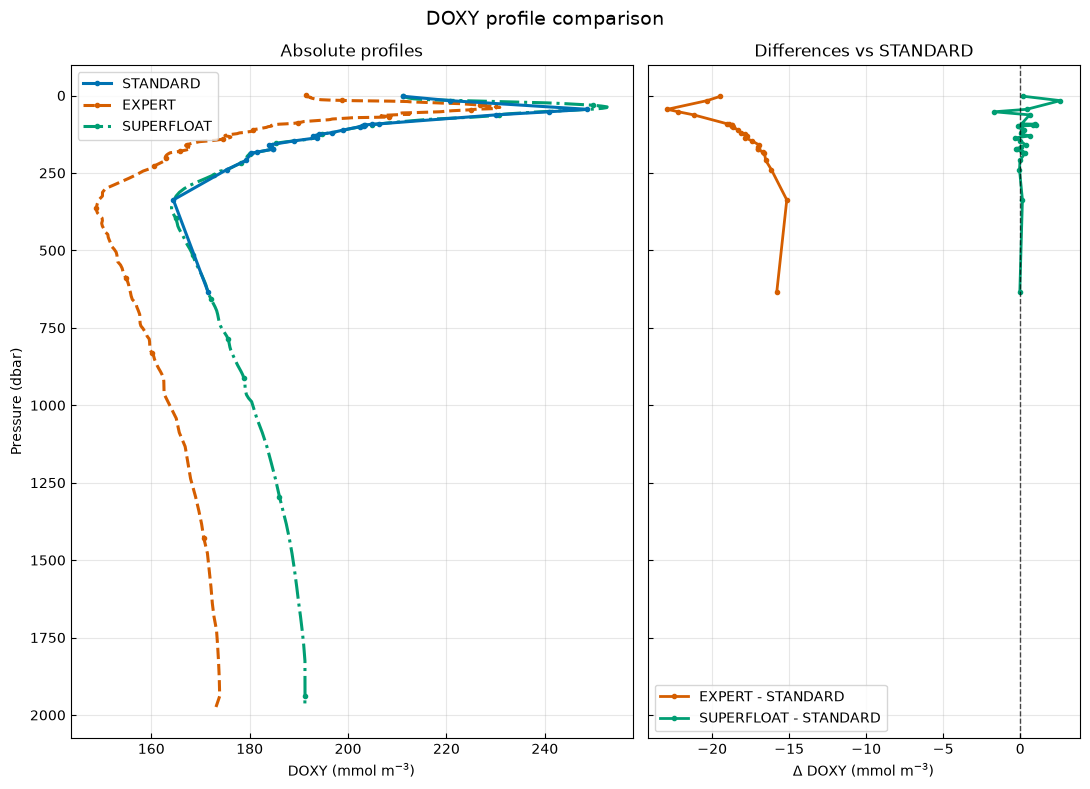

In [13]:
from src.graphics.plotter import plot_similar_comparison
name_profiles_ses = {
    "STANDARD": standard_profile,
    "EXPERT": expert_profile,
    "SUPERFLOAT": MemoryManager("data_example").load_profile("6901774_112"),
}

plot_similar_comparison(name_profiles=name_profiles_ses, attr="DOXY", title=f"6901774_112")

In [53]:
import numpy as np
import pandas as pd

def compare_datasets(expert, standard):

    vars_expert = set(expert.data_vars)
    vars_standard = set(standard.data_vars)

    common = vars_expert & vars_standard

    print("SOLO EXPERT:", sorted(vars_expert - vars_standard))
    print("SOLO STANDARD:", sorted(vars_standard - vars_expert))

    results = []

    for var in sorted(common):
        a = expert[var]
        b = standard[var]

        result = {
            "Variable": var,
            "Expert shape": a.shape,
            "Standard shape": b.shape,
        }

        if a.shape != b.shape or a.dims != b.dims:
            result["Status"] = "DIMENSIONI DIFFERENTI"
        else:
            av, bv = a.values, b.values

            identical = np.array_equal(av, bv)

            result["Identical"] = identical

            if np.issubdtype(av.dtype, np.number) and np.issubdtype(bv.dtype, np.number):

                result["Expert NaN"] = np.isnan(av).sum()
                result["Standard NaN"] = np.isnan(bv).sum()

                valid = np.isfinite(av) & np.isfinite(bv)

                if valid.any():
                    diff = np.abs(av[valid] - bv[valid])
                    result["Max difference"] = diff.max()
                    result["Mean difference"] = diff.mean()
                    result["Different values"] = (diff > 1e-8).sum()

            else:
                result["Status"] = "STRING / NON NUMERICA"

        results.append(result)

    return pd.DataFrame(results)

In [58]:
compare_datasets(expert_profile, standard_profile)

SOLO EXPERT: [np.str_('CONFIG_MISSION_NUMBER'), np.str_('PRES_ADJUSTED'), np.str_('PRES_ADJUSTED_ERROR'), np.str_('PRES_ADJUSTED_QC'), np.str_('PSAL_ADJUSTED'), np.str_('PSAL_ADJUSTED_ERROR'), np.str_('PSAL_ADJUSTED_QC'), np.str_('TEMP_ADJUSTED'), np.str_('TEMP_ADJUSTED_ERROR'), np.str_('TEMP_ADJUSTED_QC'), np.str_('VERTICAL_SAMPLING_SCHEME')]
SOLO STANDARD: [np.str_('PRES_ERROR'), np.str_('PSAL_ERROR'), np.str_('TEMP_ERROR')]


,Variable,Expert shape,Standard shape,Identical,Expert NaN,Standard NaN,Max difference,Mean difference,Different values,Status
0,CYCLE_NUMBER,"(988,)","(988,)",True,0.0,0.0,0.000000,0.000000,0.0,NaN
1,DATA_MODE,"(988,)","(988,)",True,NaN,NaN,NaN,NaN,NaN,STRING / NON NUMERICA
2,DIRECTION,"(988,)","(988,)",True,NaN,NaN,NaN,NaN,NaN,STRING / NON NUMERICA
3,PLATFORM_NUMBER,"(988,)","(988,)",True,0.0,0.0,0.000000,0.000000,0.0,NaN
4,POSITION_QC,"(988,)","(988,)",True,0.0,0.0,0.000000,0.000000,0.0,NaN
5,PRES,"(988,)","(988,)",True,0.0,0.0,0.000000,0.000000,0.0,NaN
6,PRES_QC,"(988,)","(988,)",True,0.0,0.0,0.000000,0.000000,0.0,NaN
7,PSAL,"(988,)","(988,)",False,0.0,0.0,0.009239,0.009192,988.0,NaN
8,PSAL_QC,"(988,)","(988,)",True,0.0,0.0,0.000000,0.000000,0.0,NaN
9,TEMP,"(988,)","(988,)",True,0.0,0.0,0.000000,0.000000,0.0,NaN


## Check su differenza tra params solo doxy e params completi

In [45]:
from src.graphics.plotter import plot_similar_comparison
from src.storage.cache_manager import MemoryManager

doxy_s_memory = MemoryManager(dir_name="data_s_doxy")
complete_s_memory = MemoryManager(dir_name="data_s_complete")

doxy_profiles = download_profiles("2020-07-01", "2020-08-01", params=["DOXY"])
complete_profiles = download_profiles("2020-07-01", "2020-08-01", params=['TEMP', 'PSAL', 'DOXY', 'CHLA', 'NITRATE', 'PRES'])

save_profiles(doxy_profiles, doxy_s_memory)
save_profiles(complete_profiles, complete_s_memory)

Saving 84 profiles...
data/data_s_doxy/6903262/SD6903262_095.nc SAVED.
data/data_s_doxy/6903781/SD6903781_002.nc SAVED.
data/data_s_doxy/6903263/SD6903263_094.nc SAVED.
data/data_s_doxy/6903246/SD6903246_124.nc SAVED.
data/data_s_doxy/6902904/SD6902904_154.nc SAVED.
data/data_s_doxy/6903247/SD6903247_143.nc SAVED.
data/data_s_doxy/6901775/SD6901775_155.nc SAVED.
data/data_s_doxy/6903266/SD6903266_237.nc SAVED.
data/data_s_doxy/6903237/SD6903237_169.nc SAVED.
data/data_s_doxy/6901774/SD6901774_111.nc SAVED.
data/data_s_doxy/6903250/SD6903250_140.nc SAVED.
data/data_s_doxy/6903781/SD6903781_003.nc SAVED.
data/data_s_doxy/6903262/SD6903262_096.nc SAVED.
data/data_s_doxy/6903263/SD6903263_095.nc SAVED.
data/data_s_doxy/6903246/SD6903246_125.nc SAVED.
data/data_s_doxy/6903247/SD6903247_144.nc SAVED.
data/data_s_doxy/6903266/SD6903266_238.nc SAVED.
data/data_s_doxy/6902904/SD6902904_155.nc SAVED.
data/data_s_doxy/6903237/SD6903237_170.nc SAVED.
data/data_s_doxy/6903250/SD6903250_141.nc SAVED

In [46]:
doxy_paths = doxy_s_memory.get_profiles_paths()
print(len(doxy_paths))
complete_paths = complete_s_memory.get_profiles_paths()
print(len(complete_paths))

80
4


In [47]:
doxy_e_memory = MemoryManager(dir_name="data_doxy")
complete_e_memory = MemoryManager(dir_name="data_complete")
doxy_paths = doxy_e_memory.get_profiles_paths()
print(len(doxy_paths))
complete_paths = complete_e_memory.get_profiles_paths()
print(len(complete_paths))

227
227


In [30]:
import numpy as np
import pandas as pd

def get_profile_name(p):
    import os
    return os.path.basename(p).replace("SD", "")

doxy_profile_names = set([get_profile_name(p) for p in doxy_paths])
complete_profile_names = set([get_profile_name(p) for p in complete_paths])

common_params_paths = doxy_profile_names & complete_profile_names
print(common_params_paths)

{'6903250_144.nc', '6901775_155.nc', '6901774_118.nc', '6903069_005.nc', '6902937_080.nc', '6903237_173.nc', '6902873_111.nc', '6902873_112.nc', '6901775_156.nc', '6903263_100.nc', '6902872_155.nc', '6901772_149.nc', 'S6903288_087.nc', 'S6903288_078.nc', '6901774_117.nc', '6901774_112.nc', '6902803_239.nc', '6902876_080.nc', 'S6902899_071.nc', '6902874_158.nc', '6902872_156.nc', '6903246_128.nc', '7900596_022.nc', '6902804_240.nc', '6902904_154.nc', '6902873_110.nc', 'S6903288_085.nc', '6901775_158.nc', '6903263_094.nc', '6901775_159.nc', '6902904_157.nc', 'S6903288_084.nc', '7900596_024.nc', '6903069_006.nc', '6902872_160.nc', '6903268_054.nc', '6903247_148.nc', '6903249_145.nc', '6903250_143.nc', '6902874_157.nc', '6902904_158.nc', '6903781_002.nc', '6903249_147.nc', '6902803_238.nc', 'S6903288_083.nc', '6903765_052.nc', 'S6902899_070.nc', '7900562_066.nc', '6903781_007.nc', '6903069_014.nc', '6902969_106.nc', '6902803_242.nc', 'S6902899_075.nc', '6902937_083.nc', '6902873_115.nc', '

Comparisons for 6901774_118


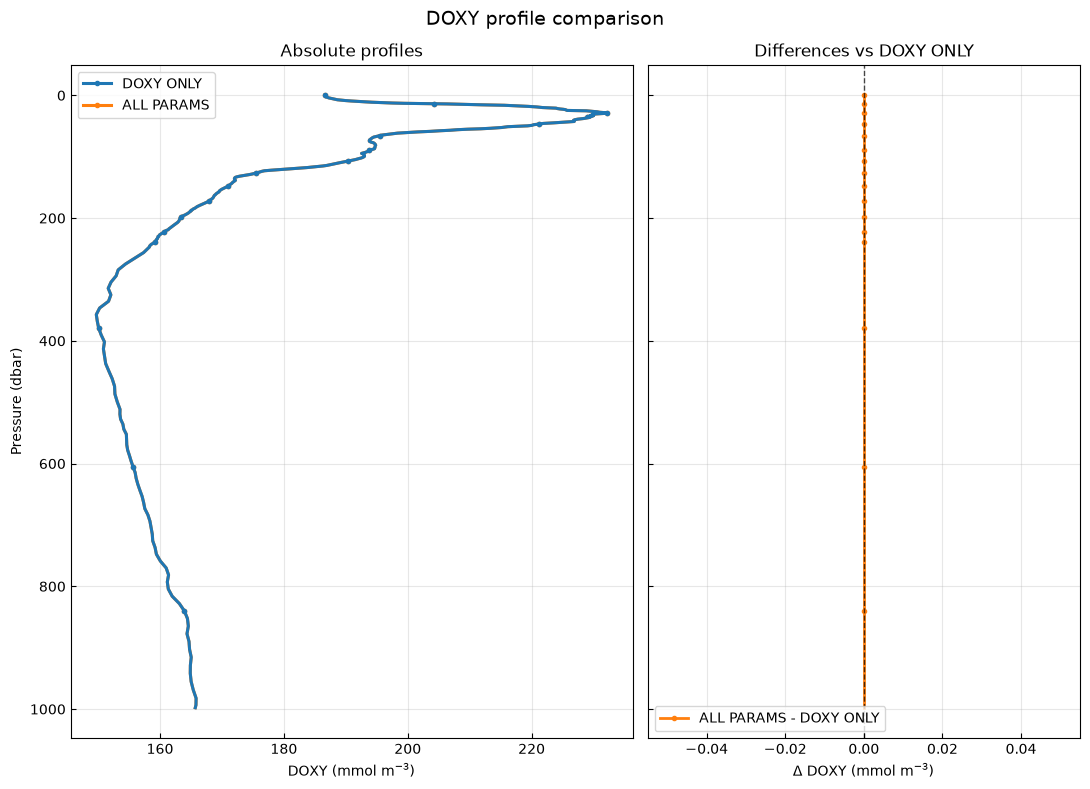

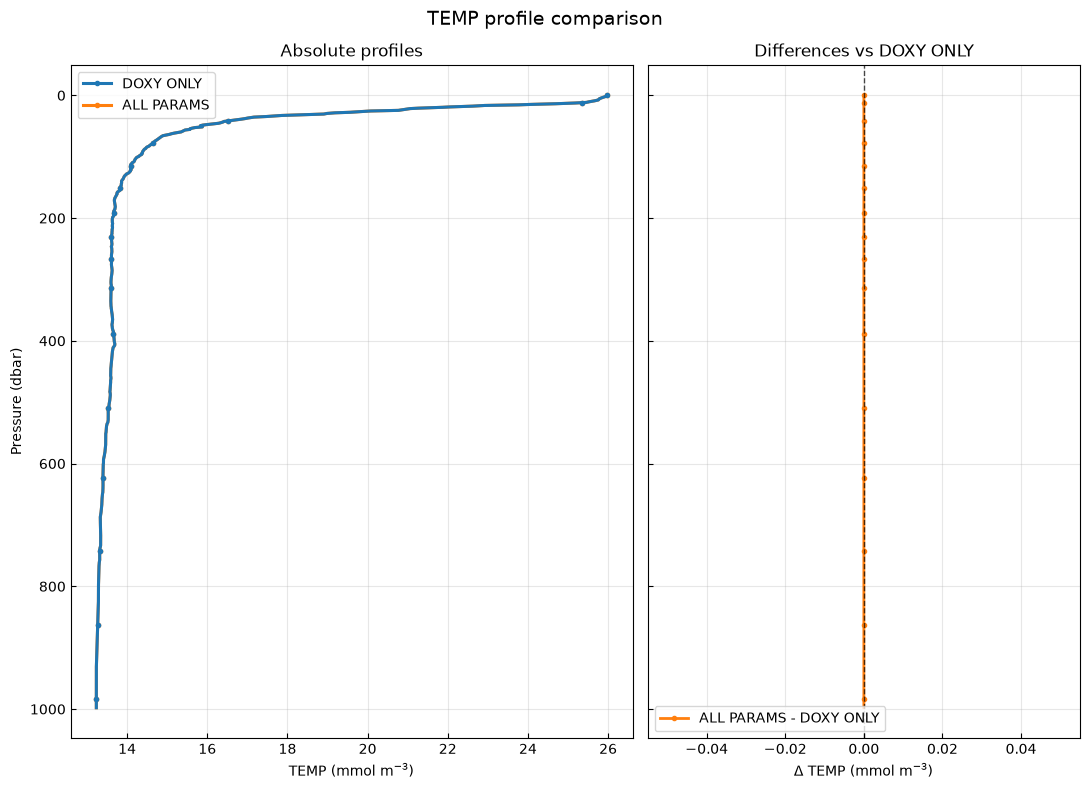

In [33]:
if len(common_params_paths) > 0:
    profile_name = common_params_paths.pop().replace(".nc", '')

    print("Comparisons for", profile_name)
    name_profiles_params = {"DOXY ONLY": doxy_s_memory.load_profile(profile_name),
                     "ALL PARAMS": complete_s_memory.load_profile(profile_name)}


    plot_similar_comparison(name_profiles=name_profiles_params, attr="DOXY", title=f"{profile_name}")
    plot_similar_comparison(name_profiles=name_profiles_params, attr="TEMP", title=f"{profile_name}")

### Integrare i netcdf con tutti i parametri insieme ai netcdf con solo doxy

# 3. Inferenza col modello


## Input formatter

In [41]:
%load_ext autoreload
%autoreload 2
from src.storage.cache_manager import MemoryManager
memory = MemoryManager(dir_name="data_complete")

complete_profiles = memory.load_profiles()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Loading 227 profiles from memory...


In [ ]:
from src.processing.input_formatter import WmoDataset

# wmo_dataset = WmoDataset()

In [43]:
for dataset in profiles:
    print(dataset)

CYCLE_NUMBER
PLATFORM_NUMBER
TIME
REFERENCE_DATE_TIME
LONGITUDE
LATITUDE
DOXY_DATA_MODE
DOXY
PRES_DOXY
TEMP
PRES_TEMP
PSAL
PRES_PSAL
CHLA
PRES_CHLA
NITRATE
PRES_NITRATE
